In [5]:

# ==========================================
# BRAIN TUMOR SEGMENTATION
# DATA PREPROCESSING
# ==========================================

from pathlib import Path
from PIL import Image, ImageOps
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

# Original dataset location
DATASET_ROOT = Path(r"D:\brain tumour\brisc2025")

# Original segmentation dataset
SEGMENTATION_ROOT = DATASET_ROOT / "segmentation_task"

# Processed dataset location
OUTPUT_ROOT = DATASET_ROOT / "segmentation_processed_256"

# Preprocessing configuration
TARGET_SIZE = (256, 256)
MASK_THRESHOLD = 128

print("Preprocessing configuration loaded!")
print("Dataset root:", DATASET_ROOT)
print("Segmentation root:", SEGMENTATION_ROOT)
print("Output root:", OUTPUT_ROOT)
print("Target image size:", TARGET_SIZE)
print("Mask threshold:", MASK_THRESHOLD)


Preprocessing configuration loaded!
Dataset root: D:\brain tumour\brisc2025
Segmentation root: D:\brain tumour\brisc2025\segmentation_task
Output root: D:\brain tumour\brisc2025\segmentation_processed_256
Target image size: (256, 256)
Mask threshold: 128


In [6]:

required_folders = [
    SEGMENTATION_ROOT / "train" / "images",
    SEGMENTATION_ROOT / "train" / "masks",
    SEGMENTATION_ROOT / "test" / "images",
    SEGMENTATION_ROOT / "test" / "masks"
]

for folder in required_folders:
    print(
        f"{'FOUND' if folder.exists() else 'NOT FOUND'}: {folder}"
    )

assert DATASET_ROOT.exists(), "Dataset root not found!"
assert all(folder.exists() for folder in required_folders), \
    "One or more dataset folders are missing!"

print("\nAll dataset paths verified successfully!")


FOUND: D:\brain tumour\brisc2025\segmentation_task\train\images
FOUND: D:\brain tumour\brisc2025\segmentation_task\train\masks
FOUND: D:\brain tumour\brisc2025\segmentation_task\test\images
FOUND: D:\brain tumour\brisc2025\segmentation_task\test\masks

All dataset paths verified successfully!


In [7]:

# ==========================================
# PREPROCESSING FUNCTIONS
# ==========================================

def resize_and_pad(image, target_size=(256, 256), interpolation=None):

    if interpolation is None:
        interpolation = Image.Resampling.BILINEAR

    # Resize while preserving aspect ratio
    resized = ImageOps.contain(
        image,
        target_size,
        method=interpolation
    )

    # Create a black canvas
    canvas = Image.new("L", target_size, 0)

    # Center the resized image
    x_offset = (target_size[0] - resized.width) // 2
    y_offset = (target_size[1] - resized.height) // 2

    canvas.paste(resized, (x_offset, y_offset))

    return canvas


def preprocess_image(image_path):

    # Load MRI as grayscale
    image = Image.open(image_path).convert("L")

    # Resize and pad
    image = resize_and_pad(
        image,
        TARGET_SIZE,
        Image.Resampling.BILINEAR
    )

    # Convert to float32 and normalize
    image_array = np.asarray(
        image,
        dtype=np.float32
    ) / 255.0

    # Add channel dimension
    image_array = image_array[..., np.newaxis]

    return image_array


def preprocess_mask(mask_path):

    # Load mask as grayscale
    mask = Image.open(mask_path).convert("L")

    # Convert into binary mask
    mask_array = np.asarray(mask)

    binary_mask = np.where(
        mask_array >= MASK_THRESHOLD,
        255,
        0
    ).astype(np.uint8)

    mask = Image.fromarray(binary_mask)

    # Resize using nearest-neighbor interpolation
    mask = resize_and_pad(
        mask,
        TARGET_SIZE,
        Image.Resampling.NEAREST
    )

    # Convert to float32 with values 0 and 1
    mask_array = (
        np.asarray(mask) >= 128
    ).astype(np.float32)

    # Add channel dimension
    mask_array = mask_array[..., np.newaxis]

    return mask_array


print("Preprocessing functions defined successfully!")


Preprocessing functions defined successfully!


In [8]:

# Select one non-standard training image
training_images = sorted(
    (SEGMENTATION_ROOT / "train" / "images").glob("*.jpg")
)

sample_path = next(
    path for path in training_images
    if Image.open(path).size != TARGET_SIZE
)

sample_mask_path = (
    SEGMENTATION_ROOT / "train" / "masks"
    / f"{sample_path.stem}.png"
)

# Preprocess sample
processed_image = preprocess_image(sample_path)
processed_mask = preprocess_mask(sample_mask_path)

# Display information
print("Sample:", sample_path.name)
print("Original dimensions:", Image.open(sample_path).size)

print("\nProcessed image:")
print("Shape:", processed_image.shape)
print("Data type:", processed_image.dtype)
print("Value range:", processed_image.min(), processed_image.max())

print("\nProcessed mask:")
print("Shape:", processed_mask.shape)
print("Data type:", processed_mask.dtype)
print("Unique values:", np.unique(processed_mask))

# Verify expected output
assert processed_image.shape == (256, 256, 1)
assert processed_mask.shape == (256, 256, 1)
assert set(np.unique(processed_mask)).issubset({0.0, 1.0})

print("\nAll sample preprocessing checks passed!")


Sample: brisc2025_train_00001_gl_ax_t1.jpg
Original dimensions: (512, 512)

Processed image:
Shape: (256, 256, 1)
Data type: float32
Value range: 0.0 0.92156863

Processed mask:
Shape: (256, 256, 1)
Data type: float32
Unique values: [0. 1.]

All sample preprocessing checks passed!


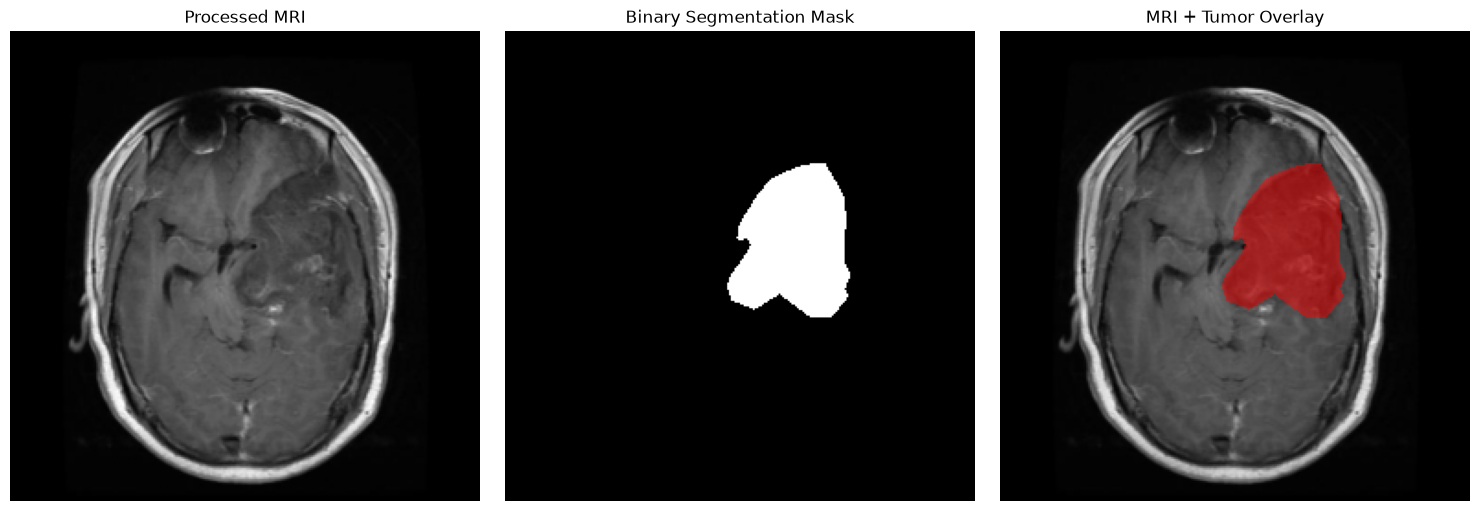

Tumor pixels: 4094
Tumor area (%): 6.247


In [9]:

# Remove channel dimension for visualization
image_display = processed_image.squeeze()
mask_display = processed_mask.squeeze()

# Create overlay
overlay = np.stack(
    [image_display] * 3,
    axis=-1
)

# Highlight tumor region in red
tumor_region = mask_display == 1

overlay[tumor_region] = (
    0.5 * overlay[tumor_region]
    + 0.5 * np.array([1.0, 0.0, 0.0])
)

# Plot results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_display, cmap="gray")
axes[0].set_title("Processed MRI")

axes[1].imshow(mask_display, cmap="gray")
axes[1].set_title("Binary Segmentation Mask")

axes[2].imshow(overlay)
axes[2].set_title("MRI + Tumor Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Tumor pixels:", int(mask_display.sum()))
print("Tumor area (%):", round(mask_display.mean() * 100, 3))


In [10]:

# ==========================================
# COMPLETE DATASET PREPROCESSING
# ==========================================

def process_dataset_split(split_name):

    image_dir = SEGMENTATION_ROOT / split_name / "images"
    mask_dir = SEGMENTATION_ROOT / split_name / "masks"

    output_image_dir = OUTPUT_ROOT / split_name / "images"
    output_mask_dir = OUTPUT_ROOT / split_name / "masks"

    output_image_dir.mkdir(parents=True, exist_ok=True)
    output_mask_dir.mkdir(parents=True, exist_ok=True)

    image_files = sorted([
        f for f in image_dir.iterdir()
        if f.is_file() and f.suffix.lower() == ".jpg"
    ])

    processed_count = 0

    for image_path in tqdm(
        image_files,
        desc=f"Processing {split_name}"
    ):

        mask_path = mask_dir / f"{image_path.stem}.png"

        if not mask_path.exists():
            raise FileNotFoundError(
                f"Missing mask: {mask_path}"
            )

        # Apply tested preprocessing functions
        image_array = preprocess_image(image_path)
        mask_array = preprocess_mask(mask_path)

        # Convert arrays back to images for storage
        image_to_save = Image.fromarray(
            (image_array.squeeze() * 255).round().astype(np.uint8)
        )

        mask_to_save = Image.fromarray(
            (mask_array.squeeze() * 255).astype(np.uint8)
        )

        # Save with matching filenames
        image_to_save.save(
            output_image_dir / f"{image_path.stem}.png"
        )

        mask_to_save.save(
            output_mask_dir / f"{image_path.stem}.png"
        )

        processed_count += 1

    print(
        f"{split_name.upper()}: "
        f"{processed_count} image-mask pairs processed."
    )


# Process both splits
process_dataset_split("train")
process_dataset_split("test")

print("\nCOMPLETE DATASET PREPROCESSING FINISHED!")
print("Output location:", OUTPUT_ROOT)


Processing train: 100%|██████████| 3933/3933 [01:19<00:00, 49.58it/s] 


TRAIN: 3933 image-mask pairs processed.


Processing test: 100%|██████████| 860/860 [00:06<00:00, 129.81it/s]

TEST: 860 image-mask pairs processed.

COMPLETE DATASET PREPROCESSING FINISHED!
Output location: D:\brain tumour\brisc2025\segmentation_processed_256


In [11]:

for split in ["train", "test"]:

    image_dir = OUTPUT_ROOT / split / "images"
    mask_dir = OUTPUT_ROOT / split / "masks"

    images = sorted(image_dir.glob("*.png"))
    masks = sorted(mask_dir.glob("*.png"))

    image_names = {f.stem for f in images}
    mask_names = {f.stem for f in masks}

    print(f"\n{split.upper()} VERIFICATION")
    print("-" * 40)

    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Missing masks:", len(image_names - mask_names))
    print("Missing images:", len(mask_names - image_names))

    assert len(images) == len(masks)
    assert image_names == mask_names

    # Verify every processed image and mask
    for image_path in images:
        mask_path = mask_dir / image_path.name

        with Image.open(image_path) as img:
            assert img.size == (256, 256)
            assert img.mode == "L"

        with Image.open(mask_path) as msk:
            assert msk.size == (256, 256)
            assert msk.mode == "L"
            assert set(np.unique(np.array(msk))).issubset({0, 255})

    print("All dimensions and mask values verified!")

print("\nALL DATASET CHECKS PASSED!")



TRAIN VERIFICATION
----------------------------------------
Images: 3933
Masks: 3933
Missing masks: 0
Missing images: 0
All dimensions and mask values verified!

TEST VERIFICATION
----------------------------------------
Images: 860
Masks: 860
Missing masks: 0
Missing images: 0
All dimensions and mask values verified!

ALL DATASET CHECKS PASSED!
